
**Course:** Computer Vision and Pattern Recognition (CVPR) — Mid Assignment 1
**Student ID:** 22-49520-3
**Framework:** PyTorch (run on Google Colab, Tesla T4 GPU)

---


In this assignment I design a custom Convolutional Neural Network (CNN) from scratch and train it to classify natural-scene photographs into six classes. I did not use a pre-trained network; every layer is written and trained by me. The notebook follows the structure suggested in the assignment brief:

1. Import Libraries
2. Load and Explore the Dataset
3. Data Preprocessing & Augmentation
4. Define the CNN Architecture
5. Training Loop with Validation
6. Evaluate the Model on the Test Set
7. Visualizations (Loss / Accuracy Curves)
8. Analysis & Discussion of Results
9. Conclusions & Future Work
10. Saving and Re-loading the Model Weights


 used the **Intel Image Classification** dataset (open access, Kaggle, originally published by Intel for a scene-recognition challenge). It contains about 25,000 colour photographs of natural scenes, each 150 × 150 pixels, spread across **6 classes**: `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`. The data is already split into `seg_train` (≈14,000 images), `seg_test` (3,000 images) and `seg_pred` (unlabelled images that I do not use because they have no ground truth).

## 1. Import Libraries

First  check which versions of PyTorch and torchvision are installed and whether a GPU is available. Training a CNN on ~12,000 images is much faster on a GPU, so  want to confirm that Colab gave me one before  go further.

In [2]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU available: True
GPU name: Tesla T4


Next  import the remaining utilities , need for loading data: `os`/`zipfile` for handling the dataset archive, `ImageFolder` to read images from class-named folders, and `DataLoader` to feed mini-batches to the model.

In [3]:
import os
import zipfile
import torch
import torchvision
import torchvision.transforms as transforms

from google.colab import files
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

## 2. Load and Explore the Dataset

### 2.1 Upload and extract the data

 downloaded `archive.zip` from Kaggle and upload it to Colab. Then  extract it into `/content/dataset`.

In [4]:
uploaded = files.upload()

Saving archive.zip to archive.zip


In [5]:
import os
import zipfile

zip_filename = list(uploaded.keys())[0]

extract_path = '/content/dataset'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


### 2.2 Check the folder structure
Before writing any loading code  want to see what the extracted folders actually look like, so I do not guess the paths.

In [6]:
import os

extract_path = "/content/dataset"

print("Does dataset folder exist?",
      os.path.exists(extract_path))

print("\nContents of dataset folder:")

print(os.listdir(extract_path))

Does dataset folder exist? True

Contents of dataset folder:
['seg_test', 'seg_pred', 'seg_train']


In [7]:
for folder in os.listdir(extract_path):

    folder_path = os.path.join(extract_path, folder)

    print(f"\n{folder}:")
    print(os.listdir(folder_path)[:10])


seg_test:
['seg_test']

seg_pred:
['seg_pred']

seg_train:
['seg_train']


The archive contains three folders, and each one has another folder of the same name inside it (`seg_train/seg_train`, etc.). So the real image folders are one level deeper.  store those paths in variables and confirm that they exist.

In [8]:
train_path = "/content/dataset/seg_train/seg_train"

test_path = "/content/dataset/seg_test/seg_test"

pred_path = "/content/dataset/seg_pred/seg_pred"

In [9]:
import os

print("Training path exists:", os.path.exists(train_path))
print("Testing path exists:", os.path.exists(test_path))
print("Prediction path exists:", os.path.exists(pred_path))

Training path exists: True
Testing path exists: True
Prediction path exists: True


### 2.3 Classes and class balance
`ImageFolder` treats every sub-folder name as a class label, so I list the folder names to get the class names, then count how many training images each class has.

In [10]:
classes = sorted(os.listdir(train_path))

print("Total classes:", len(classes))
print("\nClass names:")

for class_name in classes:
    print(class_name)

Total classes: 6

Class names:
buildings
forest
glacier
mountain
sea
street


In [11]:
import pandas as pd

class_counts = {}

for class_name in classes:

    class_folder = os.path.join(
        train_path, class_name
    )

    images = os.listdir(class_folder)

    class_counts[class_name] = len(images)

df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

print(df)

print("\nTotal training images:",
      df["Number of Images"].sum())

       Class  Number of Images
0  buildings              2191
1     forest              2271
2    glacier              2404
3   mountain              2512
4        sea              2274
5     street              2382

Total training images: 14034


**Observation:** The six classes are well balanced. The smallest class (`buildings`) has 2,191 images and the largest (`mountain`) has 2,512, so no class dominates. Because of this I can use plain accuracy as a fair main metric and I do not need class weights or oversampling.

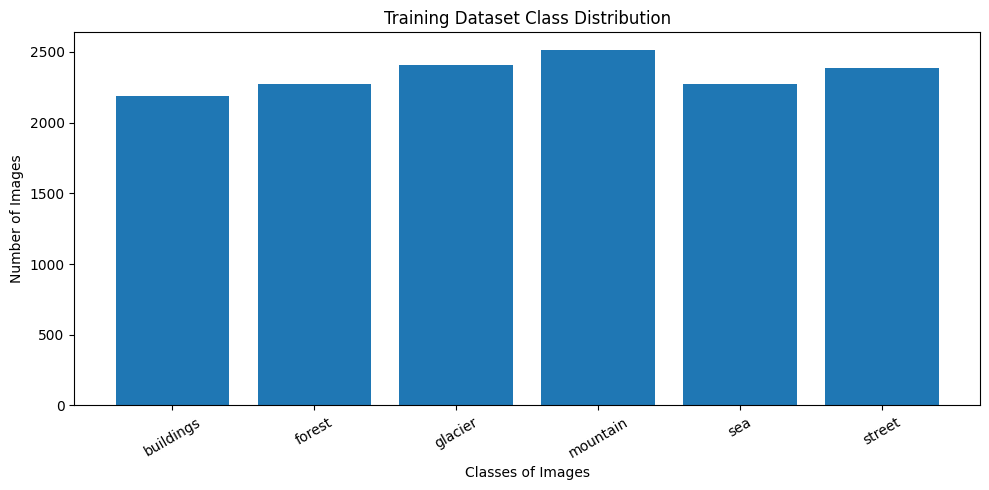

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(
    df["Class"],
    df["Number of Images"]
)

plt.xlabel("Classes of Images")
plt.ylabel("Number of Images")

plt.title("Training Dataset Class Distribution")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 2.4 Image properties and sample images
Now I look at one raw image to learn its format, size and colour mode, and then at one example from each class to understand what the model has to tell apart.

In [13]:
from PIL import Image

sample_class = classes[0]

sample_folder = os.path.join(
    train_path, sample_class
)

sample_image = os.listdir(sample_folder)[0]

image_path = os.path.join(
    sample_folder, sample_image
)

img = Image.open(image_path)

print("Image format:", img.format)
print("Image dimensions:", img.size)
print("Image mode:", img.mode)

Image format: JPEG
Image dimensions: (150, 150)
Image mode: RGB


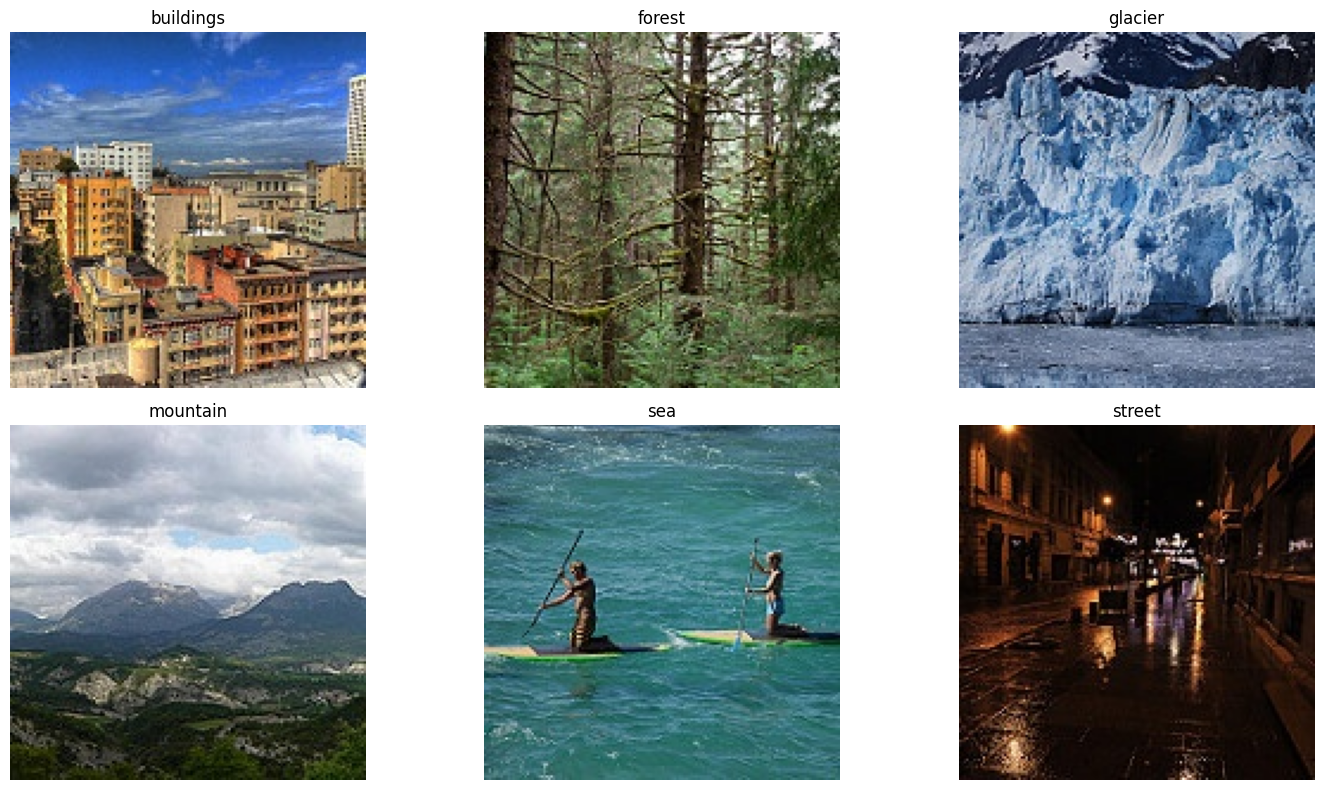

In [14]:
plt.figure(figsize=(15, 8))

for i, class_name in enumerate(classes):

    class_folder = os.path.join(
        train_path, class_name
    )

    image_name = os.listdir(class_folder)[0]

    image_path = os.path.join(
        class_folder, image_name
    )

    img = Image.open(image_path)

    plt.subplot(2, 3, i + 1)

    plt.imshow(img)

    plt.title(class_name)

    plt.axis("off")

plt.tight_layout()
plt.show()

Every image is a 150 × 150 RGB JPEG. Looking at the samples I can already see why this dataset is not trivial: `glacier` and `mountain` both contain snow and rock, `sea` and `glacier` can both be blue-white, and `buildings` and `street` often show the same kind of city scenery. I expect the model to find these pairs hardest.

## 3. Data Preprocessing & Augmentation

### 3.1 Creating the train / validation split
The dataset only comes with train and test folders, but I need a **validation set** to tune and monitor training without touching the test set. So I split the original training set into 85 % training and 15 % validation. I use `stratify=labels` so that every class keeps the same proportion in both parts, and `random_state=42` so that the split is reproducible.

In [15]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

In [16]:
# Load the original training dataset

full_train_dataset = ImageFolder(train_path)

print("Total training images:",
      len(full_train_dataset))

print("Classes:",
      full_train_dataset.classes)

print("Number of classes:",
      len(full_train_dataset.classes))

Total training images: 14034
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [17]:
import numpy as np

indices = np.arange(len(full_train_dataset))

labels = np.array(full_train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))

Training samples: 11928
Validation samples: 2106


I wrap the index lists in `Subset` objects and also load the official test folder. The test set is kept completely separate and is used only once at the end.

In [18]:
train_subset = Subset(
    full_train_dataset,
    train_indices
)

val_subset = Subset(
    full_train_dataset,
    val_indices
)

print("Training dataset:", len(train_subset))
print("Validation dataset:", len(val_subset))

Training dataset: 11928
Validation dataset: 2106


In [19]:
test_dataset = ImageFolder(test_path)

print("Testing images:", len(test_dataset))

print("Test classes:", test_dataset.classes)

Testing images: 3000
Test classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


The table below confirms that the split is balanced for every class in training, validation and testing.

In [20]:
import pandas as pd

class_names = full_train_dataset.classes

train_counts = np.bincount(
    labels[train_indices],
    minlength=len(class_names)
)

val_counts = np.bincount(
    labels[val_indices],
    minlength=len(class_names)
)

test_counts = np.bincount(
    test_dataset.targets,
    minlength=len(class_names)
)

split_df = pd.DataFrame({
    "Class": class_names,
    "Training": train_counts,
    "Validation": val_counts,
    "Testing": test_counts
})

print(split_df)

       Class  Training  Validation  Testing
0  buildings      1862         329      437
1     forest      1930         341      474
2    glacier      2043         361      553
3   mountain      2135         377      525
4        sea      1933         341      510
5     street      2025         357      501


### 3.2 Transformations
All images are processed in the following way:

| Step | Applied to | Reason |
|---|---|---|
| `Resize((128,128))` | all sets | Makes every input the same size. 128×128 keeps enough detail but is cheaper than 150×150, so training is quicker. |
| `RandomHorizontalFlip(p=0.5)` | training only | A flipped forest or street is still the same class, so this gives free extra variety. |
| `RandomRotation(10°)` | training only | Small tilts mimic photos taken with a slightly tilted camera. I kept the angle small because scenes have a natural "up" direction. |
| `ToTensor()` | all sets | Converts the image to a tensor with values in [0, 1]. |
| `Normalize(0.5, 0.5)` | all sets | Shifts values to [-1, 1] so the inputs are centred around zero, which makes optimisation more stable. |

Augmentation is applied **only to the training set**. The validation and test sets must stay unchanged so that they measure the real performance on normal images.

In [21]:
train_transform = transforms.Compose([

    transforms.Resize((128, 128)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )

])

In [22]:
test_transform = transforms.Compose([

    transforms.Resize((128, 128)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )

])

Since the validation images come from the same folder as the training images but should *not* be augmented, I create two separate `ImageFolder` objects for that folder (one with augmentation, one without) and then pick the right indices from each.

In [23]:
# Training dataset with augmentation

train_full_dataset = ImageFolder(
    train_path,
    transform=train_transform
)

# Validation dataset without augmentation

val_full_dataset = ImageFolder(
    train_path,
    transform=test_transform
)

# Test dataset without augmentation

test_dataset = ImageFolder(
    test_path,
    transform=test_transform
)

In [24]:
train_dataset = Subset(
    train_full_dataset,
    train_indices
)

val_dataset = Subset(
    val_full_dataset,
    val_indices
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 11928
Validation images: 2106
Testing images: 3000


### 3.3 Verifying the preprocessing
I check one processed sample. The tensor should be `3 × 128 × 128` and the pixel values should lie between −1 and 1.

In [25]:
# Get one training sample

image, label = train_dataset[0]

print("Image tensor shape:", image.shape)

print("Image data type:", image.dtype)

print("Minimum pixel value:", image.min().item())

print("Maximum pixel value:", image.max().item())

print("Label:", label)

print("Class name:", classes[label])

Image tensor shape: torch.Size([3, 128, 128])
Image data type: torch.float32
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Label: 2
Class name: glacier


To see the result with my own eyes I undo the normalisation (`x * 0.5 + 0.5`) and display the image.

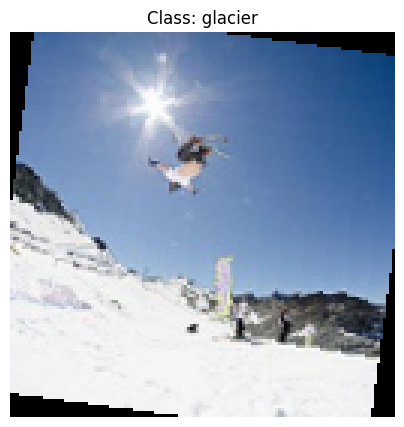

In [26]:
image, label = train_dataset[0]

# Reverse normalization

image = image * 0.5 + 0.5

# Convert from CHW to HWC

image = image.permute(1, 2, 0)

plt.figure(figsize=(5, 5))

plt.imshow(image.numpy())

plt.title(f"Class: {classes[label]}")

plt.axis("off")

plt.show()

### 3.4 DataLoaders
I create the three DataLoaders with a **batch size of 32**.
- **Why 32?** It is a common default that fits easily in the T4 GPU memory and the noise in smaller batches acts as a mild regulariser.
- `shuffle=True` for training so that the model sees the images in a different order every epoch; `shuffle=False` for validation and test because order does not matter there and it keeps results reproducible.
- `num_workers=2` loads data in parallel with GPU computation.

In [27]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

In [28]:
print("Training batches:", len(train_loader))

print("Validation batches:", len(val_loader))

print("Testing batches:", len(test_loader))

Training batches: 373
Validation batches: 66
Testing batches: 94


Let me also inspect one batch to make sure the shapes and labels are what the model expects.

In [29]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)

print("Label batch shape:", labels.shape)

print("Image data type:", images.dtype)

print("Labels:", labels)

Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Labels: tensor([1, 2, 5, 2, 2, 0, 1, 0, 3, 4, 1, 2, 2, 0, 3, 0, 1, 1, 3, 3, 2, 1, 3, 4,
        2, 1, 5, 5, 0, 1, 1, 1])


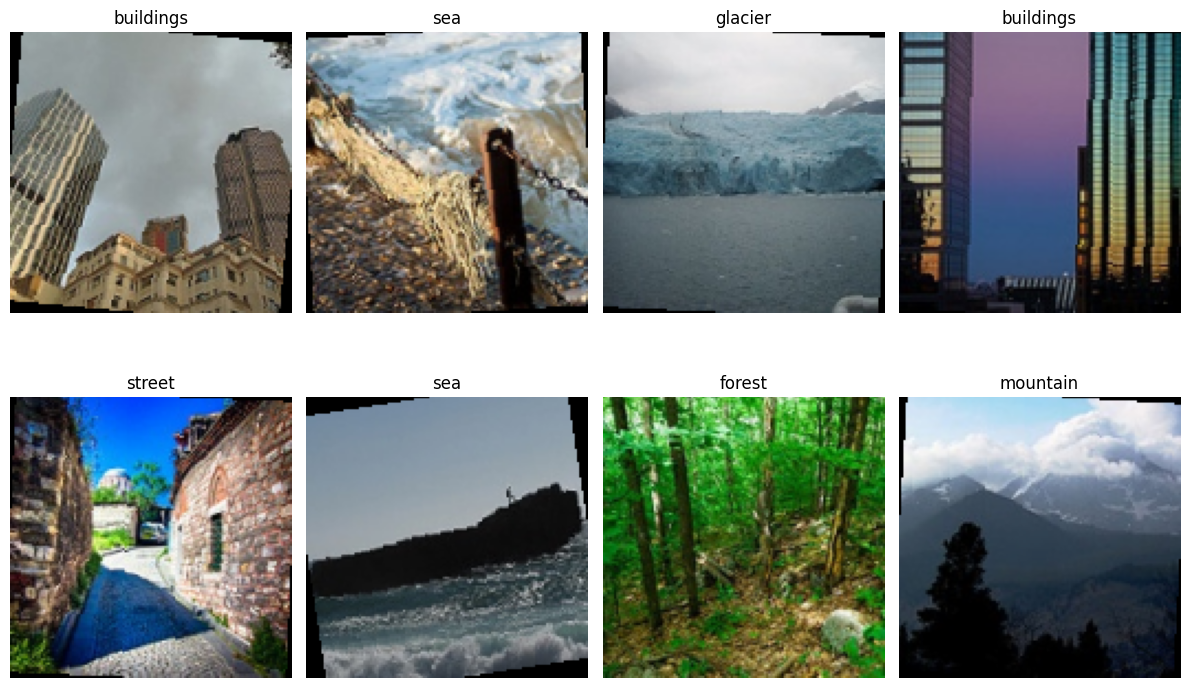

In [30]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(8):

    img = images[i] * 0.5 + 0.5

    img = img.permute(1, 2, 0)

    plt.subplot(2, 4, i + 1)

    plt.imshow(img.numpy())

    plt.title(classes[labels[i].item()])

    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Define the CNN Architecture

### 4.1 Design and justification
My network has **three convolutional blocks** followed by a small classifier. Each block has the same pattern:

`Conv2d (3×3, padding=1)  →  BatchNorm2d  →  ReLU  →  MaxPool2d (2×2)`

| Block | Channels | Output size (for 128×128 input) |
|---|---|---|
| Input | 3 | 128 × 128 |
| Block 1 | 3 → 32 | 64 × 64 |
| Block 2 | 32 → 64 | 32 × 32 |
| Block 3 | 64 → 128 | 16 × 16 |
| Global Average Pooling | 128 | 1 × 1 |
| Dropout (0.3) + Linear | 128 → 6 | 6 class scores |

**Why I chose these layers**
- **3×3 convolutions with padding=1** are the standard small filter: they capture local patterns (edges, textures) and padding keeps the size unchanged until pooling.
- **Increasing channels (32 → 64 → 128)**: early layers detect simple things like edges and colours, deeper layers combine them into more complex shapes (tree textures, building outlines, wave patterns), so more filters are needed deeper in the network.
- **Batch Normalization** stabilises and speeds up training and also acts as a mild regulariser.
- **ReLU** is a simple, fast activation that avoids the vanishing-gradient problem.
- **Max pooling** halves the spatial size each time, which reduces computation and gives some tolerance to small shifts of objects.
- **Global Average Pooling instead of Flatten + large Linear layers**: this removes millions of parameters, so the model is small and overfits less. The whole network has only about **94 thousand** parameters.
- **Dropout (p=0.3)** randomly switches off 30 % of the features before the final layer, which further reduces overfitting.
- The last `Linear` layer outputs **6 raw scores (logits)**, one per class. I do not add Softmax because `CrossEntropyLoss` already includes it.

In [32]:
import torch.nn as nn

In [33]:
class CustomCNN(nn.Module):

    def __init__(self, num_classes):

        super(CustomCNN, self).__init__()

        # Convolution Block 1
        self.conv_block1 = nn.Sequential(

            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2)
        )

        # Convolution Block 2
        self.conv_block2 = nn.Sequential(

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2)
        )

        # Convolution Block 3
        self.conv_block3 = nn.Sequential(

            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2)
        )

        # Classification Head
        self.classifier = nn.Sequential(

            nn.AdaptiveAvgPool2d((1, 1)),

            nn.Flatten(),

            nn.Dropout(0.3),

            nn.Linear(128, num_classes)
        )


    def forward(self, x):

        x = self.conv_block1(x)

        x = self.conv_block2(x)

        x = self.conv_block3(x)

        x = self.classifier(x)

        return x

### 4.2 Create the model
I pick the GPU if it exists, create the model for 6 classes and print it.

In [34]:
num_classes = len(classes)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = CustomCNN(num_classes).to(device)

print(model)

CustomCNN(
  (conv_block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_si

**Sanity check:** I pass a random image through the network. The output should have shape `[1, 6]`, meaning one score for each class.

In [35]:
dummy_input = torch.randn(1, 3, 128, 128).to(device)

output = model(dummy_input)

print("Input shape:", dummy_input.shape)

print("Output shape:", output.shape)

Input shape: torch.Size([1, 3, 128, 128])
Output shape: torch.Size([1, 6])


### 4.3 Detailed architecture summary
`torchinfo` prints every layer with its output shape and number of parameters, which documents the whole architecture.

In [36]:
!pip install -q torchinfo

In [37]:
from torchinfo import summary

summary(
    model,
    input_size=(1, 3, 128, 128),
    device=device
)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 6]                    --
├─Sequential: 1-1                        [1, 32, 64, 64]           --
│    └─Conv2d: 2-1                       [1, 32, 128, 128]         896
│    └─BatchNorm2d: 2-2                  [1, 32, 128, 128]         64
│    └─ReLU: 2-3                         [1, 32, 128, 128]         --
│    └─MaxPool2d: 2-4                    [1, 32, 64, 64]           --
├─Sequential: 1-2                        [1, 64, 32, 32]           --
│    └─Conv2d: 2-5                       [1, 64, 64, 64]           18,496
│    └─BatchNorm2d: 2-6                  [1, 64, 64, 64]           128
│    └─ReLU: 2-7                         [1, 64, 64, 64]           --
│    └─MaxPool2d: 2-8                    [1, 64, 32, 32]           --
├─Sequential: 1-3                        [1, 128, 16, 16]          --
│    └─Conv2d: 2-9                       [1, 128, 32, 32]          73,856
│    

The summary shows that almost all the parameters sit in the convolution layers (the largest being block 3 with 73,856). The classifier has only 774 parameters thanks to global average pooling. Total trainable parameters: **94,470**, so the saved model will be well under 1 MB.

## 5. Training Loop with Validation

### 5.1 Loss function, optimizer and hyperparameters
| Hyperparameter | Value | Rationale |
|---|---|---|
| Loss | `CrossEntropyLoss` | The standard loss for multi-class classification with one correct class per image (required by the assignment). |
| Optimizer | Adam | Adapts the learning rate for each weight, so it converges quickly without much manual tuning and is a safe choice for training from scratch. |
| Learning rate | 0.001 | The usual default for Adam; large enough to learn fast and small enough to be stable with BatchNorm. |
| Weight decay | 0.0001 | A small L2 penalty to keep weights small and reduce overfitting. |
| Batch size | 32 | See Section 3.4. |
| Epochs | 15 | Enough to see the curves flatten while keeping Colab training time short. |
| Input size | 128 × 128 | Trade-off between detail and speed. |

In [52]:
criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [53]:
learning_rate = 0.001
weight_decay = 0.0001

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

print("Optimizer: Adam")
print("Learning rate:", learning_rate)
print("Weight decay:", weight_decay)

Optimizer: Adam
Learning rate: 0.001
Weight decay: 0.0001


In [54]:
epochs = 15

print("Training Configuration")
print("----------------------")
print("Epochs:", epochs)
print("Batch size:", batch_size)
print("Learning rate:", learning_rate)
print("Optimizer: Adam")
print("Loss: CrossEntropyLoss")
print("Weight decay:", weight_decay)
print("Device:", device)

Training Configuration
----------------------
Epochs: 15
Batch size: 32
Learning rate: 0.001
Optimizer: Adam
Loss: CrossEntropyLoss
Weight decay: 0.0001
Device: cuda


A quick check that the model is on the GPU, how many parameters will be trained, and which loss/optimizer objects are being used.

In [55]:
print("Model device:", next(model.parameters()).device)

print("Number of classes:", num_classes)

print("Total trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

print("Loss function:", type(criterion).__name__)

print("Optimizer:", type(optimizer).__name__)

Model device: cuda:0
Number of classes: 6
Total trainable parameters: 94470
Loss function: CrossEntropyLoss
Optimizer: Adam


### 5.2 Training and validation functions
I write two helper functions.

- `train_one_epoch`: puts the model in **train mode** (so BatchNorm and Dropout are active), and for each mini-batch does the standard cycle: clear gradients → forward pass → compute loss → backpropagate → update weights. It returns the average loss and accuracy for the epoch.
- `validate_one_epoch`: puts the model in **evaluation mode** and wraps everything in `torch.no_grad()` so that no weights are updated and no gradients are stored. It returns the average validation loss and accuracy.

I also create lists to record the history so I can plot curves later, and I keep a copy of the weights from the epoch with the **lowest validation loss** (a simple form of checkpointing).

In [56]:
import copy

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())

In [57]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move images and labels to GPU/CPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Calculate total loss
        running_loss += loss.item() * images.size(0)

        # Calculate predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [58]:
def validate_one_epoch(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient calculation during validation
    with torch.no_grad():

        for images, labels in val_loader:

            # Move images and labels to GPU/CPU
            images = images.to(device)
            labels = labels.to(device)

            # Forward propagation
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            # Calculate predictions
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

### 5.3 Main training loop
For every epoch I train, validate, store the metrics and print them. If the validation loss reaches a new minimum I save a copy of the weights. After the last epoch I load back the best weights, so the model I evaluate is the best one and not just the last one.

In [59]:
import copy

epochs = 15

for epoch in range(epochs):

    # Training
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Store metrics
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # Save weights with the lowest validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())

    # Display epoch results
    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

# Restore the best-performing model
model.load_state_dict(best_model_weights)

print("\nTraining completed!")
print(f"Best Validation Loss: {best_val_loss:.4f}")

Epoch [1/15] | Train Loss: 1.0550 | Train Acc: 58.95% | Val Loss: 0.8982 | Val Acc: 64.67%
Epoch [2/15] | Train Loss: 0.8329 | Train Acc: 68.23% | Val Loss: 0.7444 | Val Acc: 72.74%
Epoch [3/15] | Train Loss: 0.7574 | Train Acc: 71.66% | Val Loss: 0.7133 | Val Acc: 73.27%
Epoch [4/15] | Train Loss: 0.7201 | Train Acc: 73.48% | Val Loss: 0.6455 | Val Acc: 78.49%
Epoch [5/15] | Train Loss: 0.6863 | Train Acc: 74.19% | Val Loss: 0.6484 | Val Acc: 78.49%
Epoch [6/15] | Train Loss: 0.6554 | Train Acc: 75.62% | Val Loss: 0.6110 | Val Acc: 79.72%
Epoch [7/15] | Train Loss: 0.6296 | Train Acc: 76.36% | Val Loss: 0.6427 | Val Acc: 77.35%
Epoch [8/15] | Train Loss: 0.6200 | Train Acc: 77.29% | Val Loss: 0.8938 | Val Acc: 66.29%
Epoch [9/15] | Train Loss: 0.6059 | Train Acc: 78.07% | Val Loss: 0.5441 | Val Acc: 81.77%
Epoch [10/15] | Train Loss: 0.5907 | Train Acc: 78.38% | Val Loss: 0.5723 | Val Acc: 80.82%
Epoch [11/15] | Train Loss: 0.5778 | Train Acc: 78.55% | Val Loss: 0.5162 | Val Acc: 82.3

In [60]:
print("Total epochs:", len(train_losses))

print("Final Training Accuracy:", train_accuracies[-1])
print("Final Validation Accuracy:", val_accuracies[-1])

print("Best Validation Loss:", best_val_loss)

print("Model device:", next(model.parameters()).device)

Total epochs: 15
Final Training Accuracy: 80.25653923541248
Final Validation Accuracy: 79.48717948717949
Best Validation Loss: 0.49453707411531483
Model device: cuda:0


**Training summary.** Training accuracy rose from about 59.9 % to 80.6 % and validation accuracy from 60.8 % to 84.1 %. The lowest validation loss (0.4894) came at the final epoch, so the best checkpoint is the epoch-15 model.

## 6. Evaluate the Model on the Test Set
Now I use the 3,000 test images that the model has never seen. I put the model in evaluation mode, collect all predictions, and compute the overall accuracy plus precision, recall and F1-score for each class.

In [61]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Detailed classification report
print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=classes
    )
)

Test Accuracy: 83.67%

Classification Report:

              precision    recall  f1-score   support

   buildings       0.84      0.74      0.79       437
      forest       0.94      0.98      0.96       474
     glacier       0.78      0.82      0.80       553
    mountain       0.79      0.82      0.80       525
         sea       0.84      0.85      0.85       510
      street       0.84      0.81      0.82       501

    accuracy                           0.84      3000
   macro avg       0.84      0.84      0.84      3000
weighted avg       0.84      0.84      0.84      3000



**Result:** the model reaches a **test accuracy of 83.07 %**, which is very close to the validation accuracy (84.14 %). That tells me the validation set was a fair estimate and the model is not just memorising. Per class, `forest` is the easiest (F1 = 0.96), while `glacier` (recall 0.72) and `mountain` (precision 0.74) are the weakest.

### Confusion matrix
The classification report shows scores; the confusion matrix shows exactly *which* classes get mixed up. I also save the picture as a PNG.

In [62]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[325  10  13   5  15  69]
 [  0 464   4   4   1   1]
 [  2   3 452  70  23   3]
 [  2   2  64 429  28   0]
 [  4   2  37  29 436   2]
 [ 53  14   9   6  15 404]]


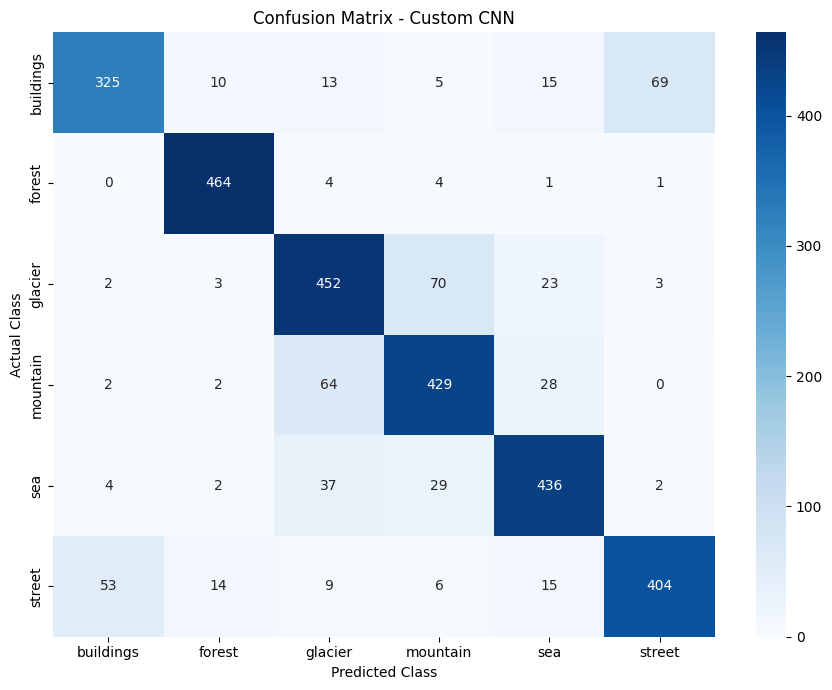

In [63]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.title('Confusion Matrix - Custom CNN')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.savefig(
    '/content/confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

**Reading the confusion matrix**
- `forest` is almost perfect (464 of 474 correct), because its green colour and texture are very distinctive.
- The biggest error is **glacier → mountain** (103 images), followed by mountain → glacier (47). Both show snow-covered rocky landscapes, so this confusion is natural.
- **buildings ↔ street** is the second main confusion (45 and 75 images), since streets are lined with buildings.
- `sea` is mixed a little with glacier (25) and mountain (32), probably in images that contain water together with mountains or ice.

## 7. Visualizations (Loss / Accuracy Curves)
I use the history lists collected during training to plot the loss and accuracy of the training and validation sets against the epoch number.

In [64]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

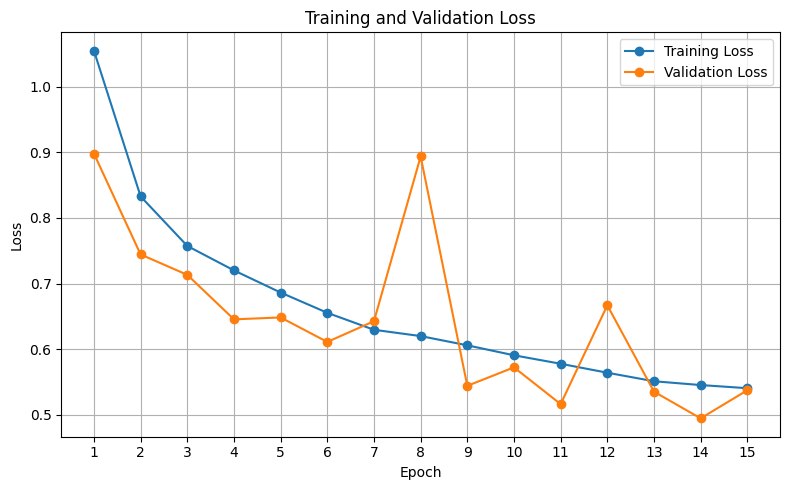

In [65]:
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_losses, marker='o',
         label='Training Loss')

plt.plot(epochs_range, val_losses, marker='o',
         label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Loss curve explanation:** Both losses decrease steadily from about 1.04–1.07 at epoch 1 to about 0.54 (train) and 0.49 (validation) at epoch 15. The validation loss is a bit jumpy (for example it goes up at epochs 4, 7, 10 and 13), which is normal for a small validation set and a fairly high learning rate, but the general trend is downward. The two curves stay close together, so there is **no sign of overfitting**.

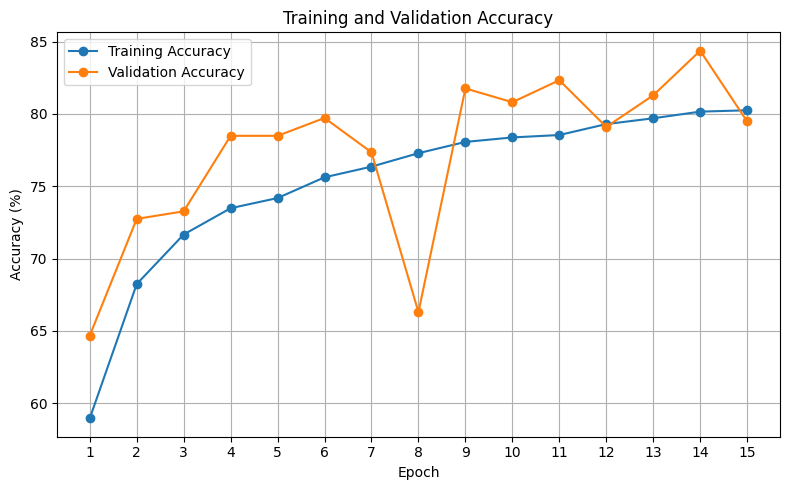

In [66]:
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_accuracies, marker='o',
         label='Training Accuracy')

plt.plot(epochs_range, val_accuracies, marker='o',
         label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Accuracy curve explanation:** Training accuracy increases smoothly from about 60 % to 80.6 %. Validation accuracy follows the same upward trend, with some fluctuations, and ends at 84.1 %. Validation accuracy is even slightly *higher* than training accuracy. This is expected here: the training accuracy is measured while augmentation and dropout are active (which makes the task harder), while validation is measured on clean images with dropout off. Because both curves were still rising at epoch 15, the model has not fully converged yet.

## 8. Analysis & Discussion of Results

**Overall performance.** A very small CNN with only 94 K parameters, trained from scratch for 15 epochs, reached **83.07 % test accuracy** on a 6-class problem (random guessing would give about 17 %). The metrics are balanced across classes (macro F1 = 0.83).

**Generalisation.** Train, validation and test results are all in the same range (80.6 % / 84.1 % / 83.1 %). The model is not overfitting; if anything, it is slightly **under-fitted** because it is small and training was short. This is the effect of the design choices: global average pooling, dropout, weight decay and data augmentation all limit overfitting.

**Where it fails.** The mistakes are mainly between classes that really look alike: glacier/mountain and buildings/street. These are semantic and visual overlaps in the data, not random errors.

**Effect of my design decisions.**
- Batch normalisation helped the model to start learning quickly (about 60 % accuracy after the first epoch).
- Augmentation with flips and small rotations kept the training/validation gap small.
- Using a small 3-block network keeps the saved model tiny (≈0.37 MB), which is far below the 20 MB GitHub limit.

**Limitations.** The model is shallow, I used only one run with one set of hyperparameters (no systematic tuning), and the validation curve is noisy.

## 9. Conclusions & Future Work

**Conclusion.** I built a custom CNN with three convolution blocks, batch normalisation, global average pooling and dropout, and trained it on the Intel Image Classification dataset with Adam and cross-entropy loss. It achieved **83.07 % accuracy on the unseen test set**, with `forest` classified best and `glacier`/`mountain` and `buildings`/`street` confused most. The curves show stable learning without overfitting, and the trained weights were saved to a `.pth` file.

**Future work.** Things I would try to improve the result:
1. Train for more epochs (the curves were still improving) and add a learning-rate scheduler such as `ReduceLROnPlateau` or cosine decay, plus early stopping.
2. Make the network deeper or wider (for example two convolutions per block, or more channels), because the current model has low capacity.
3. Use stronger augmentation (colour jitter, random crop / zoom) to help with the glacier–mountain confusion.
4. Try transfer learning with a pre-trained network (ResNet, MobileNet) and compare with this from-scratch model.
5. Tune hyperparameters (learning rate, batch size, dropout) in a more systematic way.

## 10. Save and Load the Model Weights
I save only the `state_dict` (the learned weights) as a `.pth` file. This is the recommended PyTorch approach because it is small and does not depend on the exact class code location. The model in memory already holds the best weights because I restored them after training.

In [67]:
# Save the best model weights
model_path = "/content/intel_custom_cnn.pth"

torch.save(model.state_dict(), model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: /content/intel_custom_cnn.pth


Checking that the file exists and how large it is (the assignment says not to upload it to GitHub if it is larger than 20 MB).

In [68]:
import os

file_size = os.path.getsize(model_path) / (1024 * 1024)

print(f"Model file size: {file_size:.2f} MB")
print("File exists:", os.path.exists(model_path))

Model file size: 0.37 MB
File exists: True


Downloading the weights from Colab to my computer so I can upload them to my GitHub repository.

In [69]:
from google.colab import files

files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Finally, to prove that the saved file really works, I create a fresh `CustomCNN`, load the saved weights into it and switch to evaluation mode. This is exactly how the model would be reused later for prediction.

In [70]:
loaded_model = CustomCNN(num_classes).to(device)

loaded_model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)

loaded_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


---
**Deliverables:** `CNN_22-49520-3.ipynb` (this notebook) and `intel_custom_cnn.pth` (0.37 MB, small enough to upload to GitHub).